<a href="https://colab.research.google.com/github/Batmansanty49/ProcesamientoDigitalDeSe-alesProyectoFinal/blob/main/ProyectoFinal_SAHN_EOB_SRR.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Proyecto final**

Integrantes:

* Hernandez Nativitas Sofia Alejandra
* Ortiz Briseño Emiliano
* Ruiz Ramírez Santiago

# 1. Preparación y carga de audios.

Aquí importamos las librerías necesarias para el procesamiento de las señales (NumPy, SciPy) y visualización. También cargamos los audios muestreados a 16 kHz (Nyquist = 8 kHz) y generamos reproductores interactivos para que escuches las señales originales contaminadas.

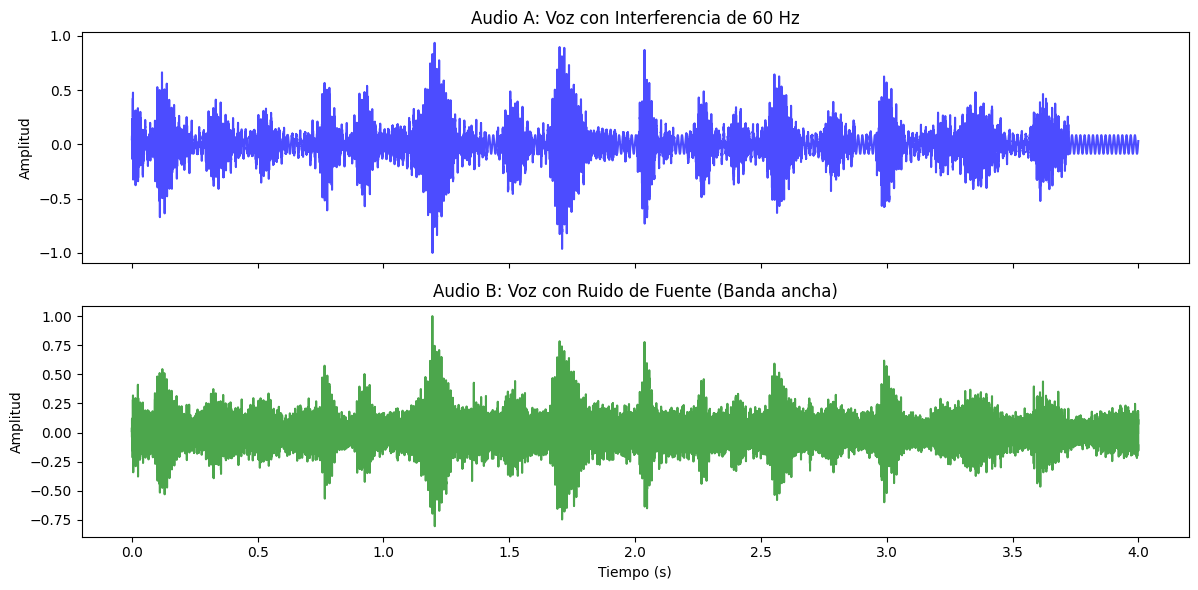

Escuchar Audio A (60 Hz):


Escuchar Audio B (Banda Ancha):


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

# Archivos
file_A = 'PDS_voz_60Hz_4s.wav'
file_B = 'PDS_voz_fuente_simulada_4s.wav'

# Cargar audios
fs, audio_A = wavfile.read(file_A)
_, audio_B = wavfile.read(file_B)

# Normalización de los audios para evitar saturación
audio_A = audio_A / np.max(np.abs(audio_A))
audio_B = audio_B / np.max(np.abs(audio_B))

# Vector de tiempo
t = np.arange(len(audio_A)) / fs

# Graficamos en el tiempo
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
ax1.plot(t, audio_A, color='blue', alpha=0.7)
ax1.set_title('Audio A: Voz con Interferencia de 60 Hz')
ax1.set_ylabel('Amplitud')

ax2.plot(t, audio_B, color='green', alpha=0.7)
ax2.set_title('Audio B: Voz con Ruido de Fuente (Banda ancha)')
ax2.set_xlabel('Tiempo (s)')
ax2.set_ylabel('Amplitud')
plt.tight_layout()
plt.show()

print("Escuchar Audio A (60 Hz):")
display(Audio(audio_A, rate=fs))
print("Escuchar Audio B (Banda Ancha):")
display(Audio(audio_B, rate=fs))

# 2. Diagnóstico y FFT por ventanas.

Aquí implementamos el análisis espectral dividiendo la señal en segmentos configurables. También aplicamos una ventana Hann antes de calcular la FFT para disminuir la fuga espectral y graficamos el espectro promedio.

Análisis Espectral - Audio A:


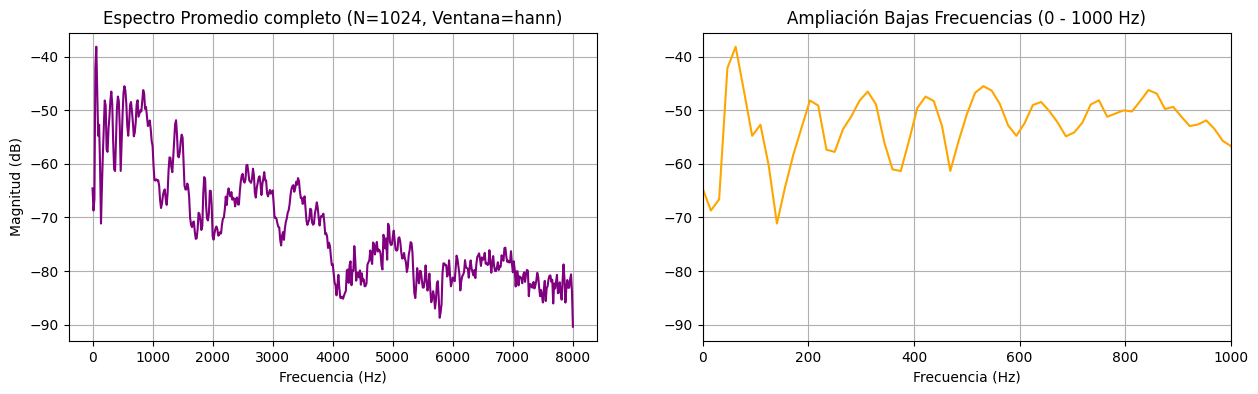

Análisis Espectral - Audio B:


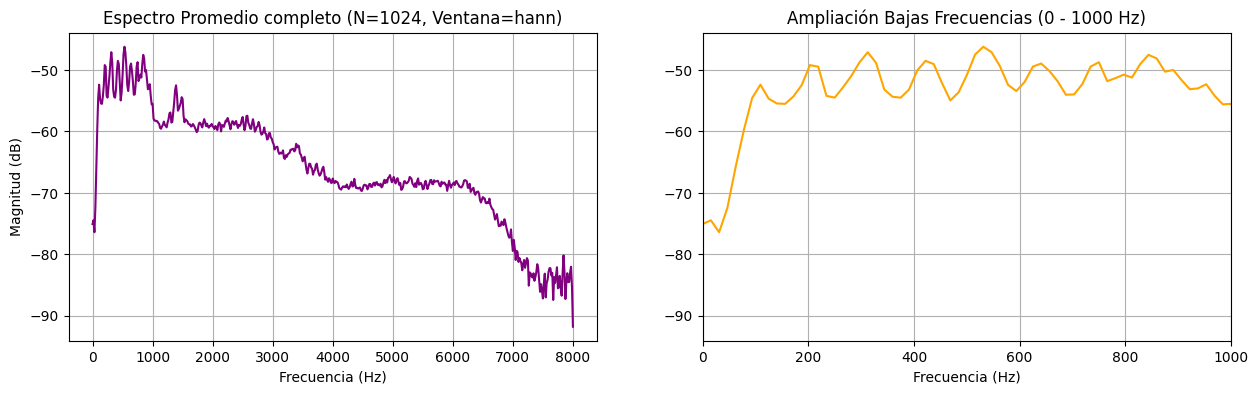

In [ ]:
def analizar_espectro(senal, fs, N_fft, window_type='hann'):
    # Calcular Densidad Espectral de Potencia promedio usando el método de Welch
    # Esto divide internamente en segmentos, aplica la ventana y promedia las FFTs
    frecuencias, pxx = signal.welch(senal, fs, window=window_type, nperseg=N_fft, noverlap=N_fft//2)
    magnitud_db = 10 * np.log10(pxx)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))

    # Vista completa
    ax1.plot(frecuencias, magnitud_db, color='purple')
    ax1.set_title(f'Espectro Promedio completo (N={N_fft}, Ventana={window_type})')
    ax1.set_xlabel('Frecuencia (Hz)')
    ax1.set_ylabel('Magnitud (dB)')
    ax1.grid(True)

    # Ampliación de bajas frecuencias (0 a 1000 Hz) para ver bien los 60 Hz
    ax2.plot(frecuencias, magnitud_db, color='orange')
    ax2.set_title('Ampliación Bajas Frecuencias (0 - 1000 Hz)')
    ax2.set_xlim(0, 1000)
    ax2.set_xlabel('Frecuencia (Hz)')
    ax2.grid(True)
    plt.show()

# Parámetros
longitud_ventana = 1024  # 256, 512, 1024, 2048
# Ahí pueden jugar con los valores, se va volviendo más puntiaguda conforme aumentan vaya
tipo_ventana = 'hann'    # pueden cambiar a 'boxcar' (rectangular) soloa para ver la diferencia x,p

print("Análisis Espectral - Audio A:")
analizar_espectro(audio_A, fs, N_fft=longitud_ventana, window_type=tipo_ventana)

print("Análisis Espectral - Audio B:")
analizar_espectro(audio_B, fs, N_fft=longitud_ventana, window_type=tipo_ventana)

# 3. Diseño FIR por ventanas y Plano Z.

Con base en el diagnóstico anterior, diseñamos los filtros FIR utilizando el método de ventanas (Hann) para truncar la respuesta al impulso ideal.   

* Audio A: Configuramos un filtro rechaza-banda (bandstop) para centrarnos en los 60 Hz.
* Audio B: Configuramos un filtro pasa-bajas (lowpass), considerando que la voz útil está mayormente debajo de los 4 kHz.

En está parte es dondé extraemos los coeficientes ($h[n]$), se buscan las raíces para graficar los ceros en el Plano Z y proceder a la respuesta en frecuencia.

Análisis Filtro FIR para Audio A (Notch 60Hz):


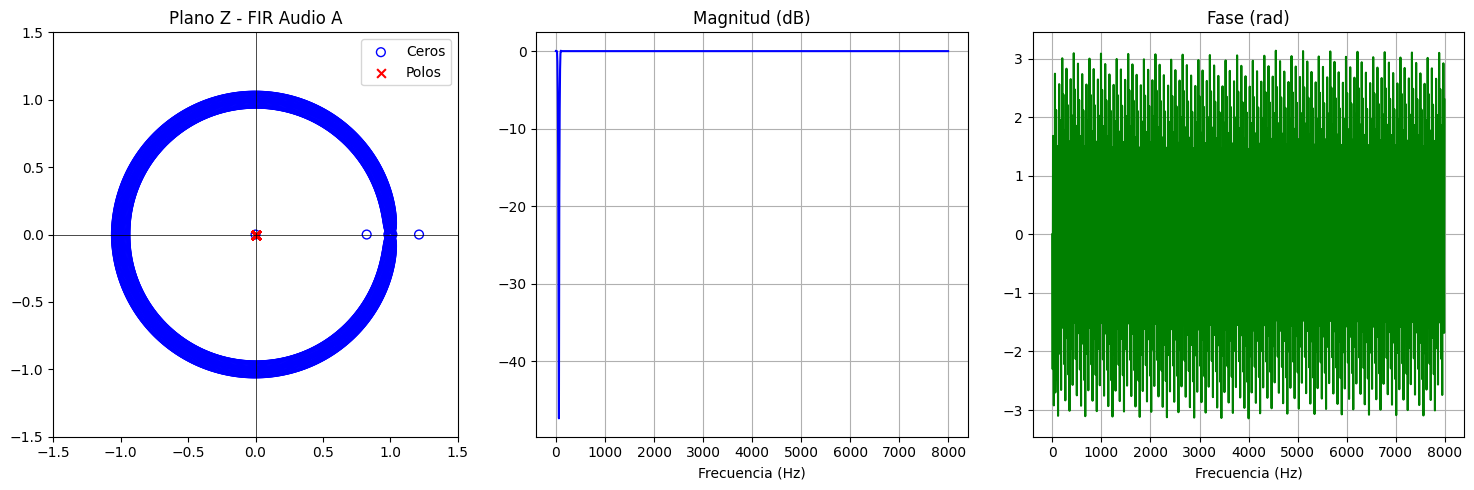

Análisis Filtro FIR para Audio B (Pasa-banda 160-1850 Hz):


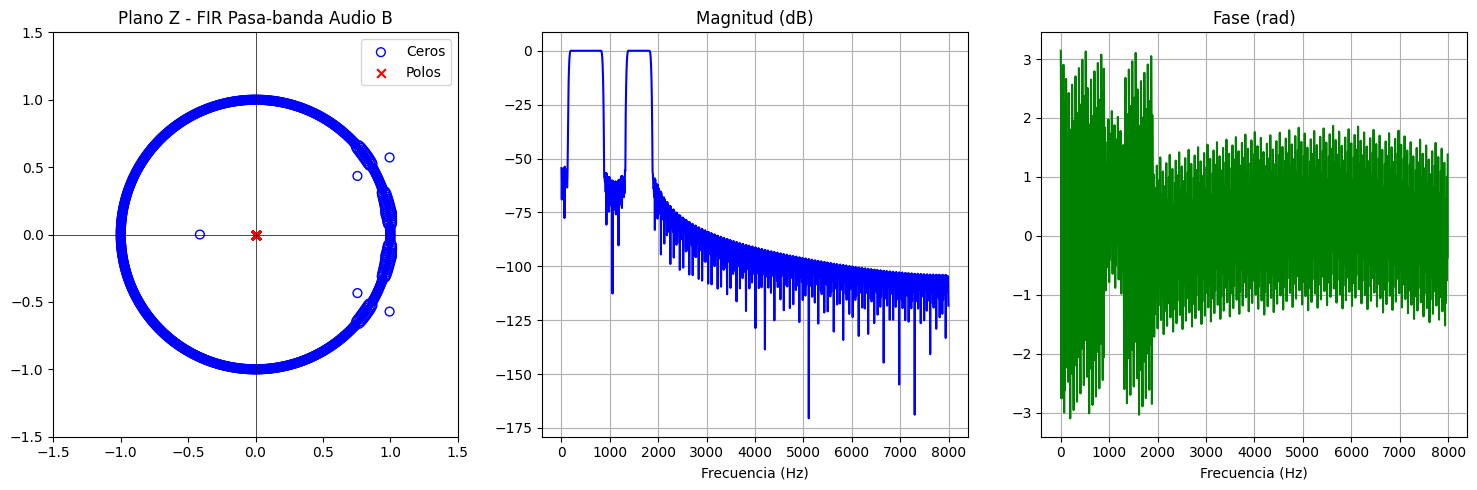

In [ ]:
def graficar_analisis_filtro(b, a=[1.0], titulo="Filtro"):
    # Obtención de los ceros y polos
    ceros = np.roots(b)
    polos = np.roots(a) if len(a) > 1 else np.zeros(len(ceros)) # En FIR, los polos están en el origen

    # Respuesta en frecuencia
    w, h = signal.freqz(b, a, worN=1024)
    frec = w * fs / (2 * np.pi)

    fig = plt.figure(figsize=(15, 5))

    # Plano Z
    ax1 = plt.subplot(1, 3, 1)
    ax1.add_patch(plt.Circle((0, 0), 1, color='gray', fill=False, linestyle='--'))
    ax1.scatter(np.real(ceros), np.imag(ceros), s=40, facecolors='none', edgecolors='b', label='Ceros')
    ax1.scatter(np.real(polos), np.imag(polos), s=40, marker='x', color='r', label='Polos')
    ax1.axhline(0, color='black', lw=0.5)
    ax1.axvline(0, color='black', lw=0.5)
    ax1.set_title(f'Plano Z - {titulo}')
    ax1.set_xlim([-1.5, 1.5]); ax1.set_ylim([-1.5, 1.5])
    ax1.set_aspect('equal')
    ax1.legend()

    # Magnitud
    ax2 = plt.subplot(1, 3, 2)
    ax2.plot(frec, 20 * np.log10(np.abs(h)), 'b')
    ax2.set_title('Magnitud (dB)')
    ax2.set_xlabel('Frecuencia (Hz)')
    ax2.grid(True)

    # Fase
    ax3 = plt.subplot(1, 3, 3)
    ax3.plot(frec, np.angle(h), 'g')
    ax3.set_title('Fase (rad)')
    ax3.set_xlabel('Frecuencia (Hz)')
    ax3.grid(True)

    plt.tight_layout()
    plt.show()


orden_FIR_A = 1501  # Debe ser impar para bandstop
frec_notch = [40, 80] # Banda de rechazo para aislar 60 Hz

# Coeficientes h[n] usando ventana Hann
fir_A_taps = signal.firwin(orden_FIR_A, frec_notch, pass_zero='bandstop', window='hann', fs=fs)

# FILTROS PARA EL AUDIO B
orden_FIR_B = 901
banda_voz_B = [160, 850, 1350, 1850]
fir_B_taps = signal.firwin(orden_FIR_B, banda_voz_B, pass_zero=False, window='hamming', fs=fs)

print("Análisis Filtro FIR para Audio A (Notch 60Hz):")
graficar_analisis_filtro(fir_A_taps, titulo="FIR Audio A")

print("Análisis Filtro FIR para Audio B (Pasa-banda 160-1850 Hz):")
graficar_analisis_filtro(fir_B_taps, titulo="FIR Pasa-banda Audio B")

## 4. IIR

Aquí diseñamos filtros IIR de biblioteca para compararlos técnica y auditivamente con los FIR.
Usamos un IIR Notch específico para el Audio A, y un IIR Butterworth para el Audio B.

Análisis Filtro IIR para Audio A:


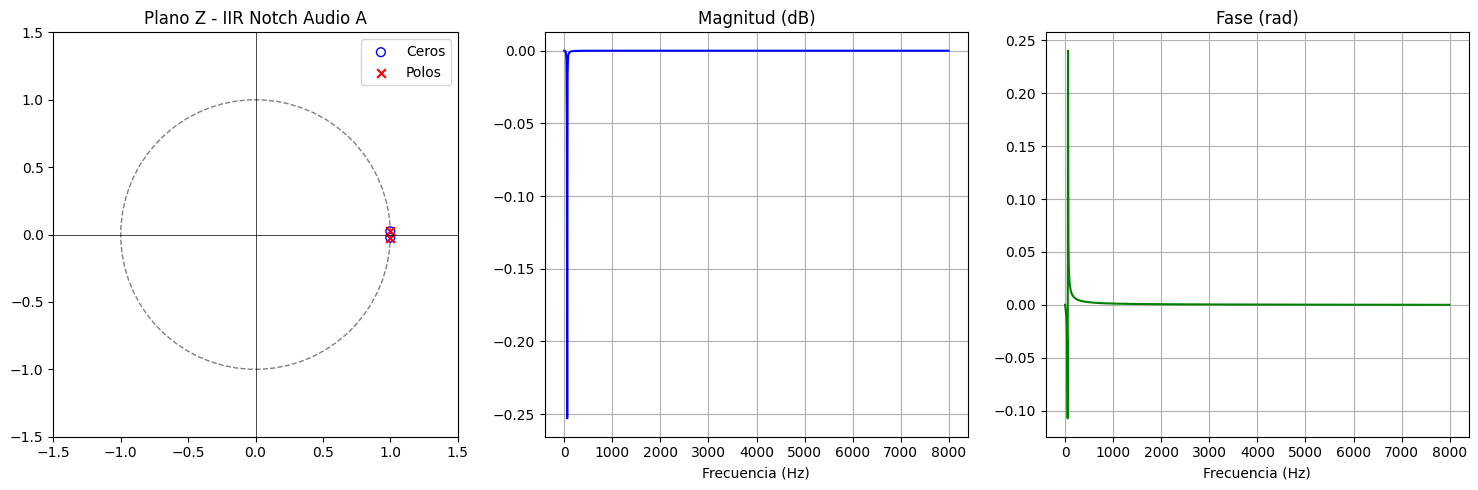

Análisis Filtro IIR para Audio B:


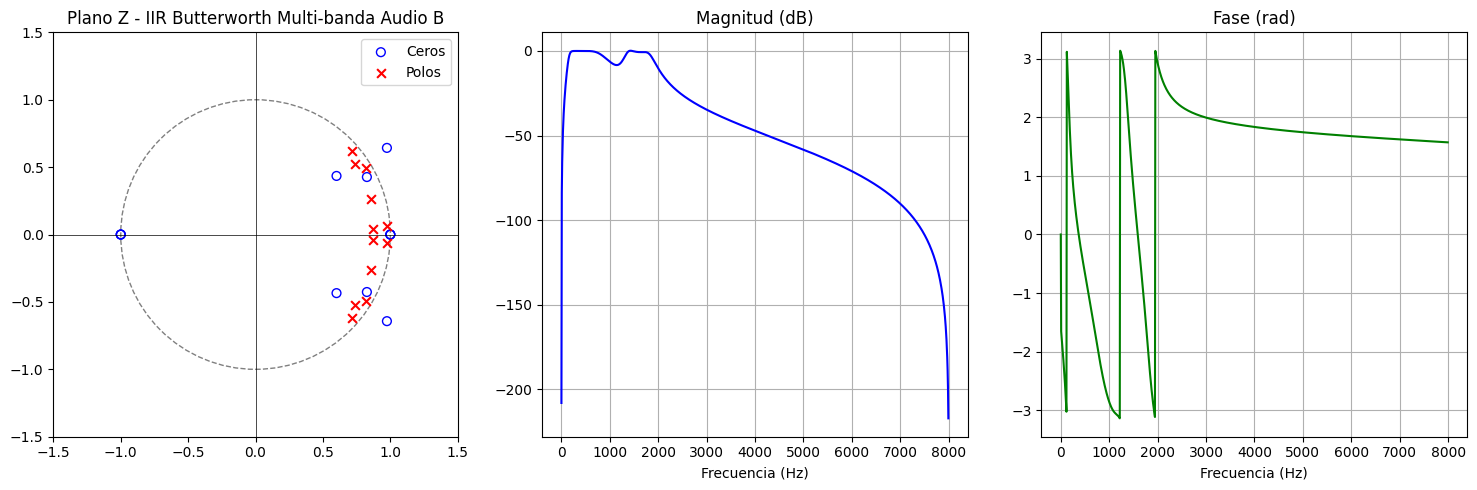

In [ ]:
# Si quieren juguen con los parámetros de esta vaina, chance y encuentran unos mejores
# IIR
# Audio A: Notch IIR
Q_notch = 50.0  # Factor de calidad (mayor Q = muesca más estrecha)
b_iir_A, a_iir_A = signal.iirnotch(60.0, Q_notch, fs)

# Audio B
orden_IIR_B = 3
b1, a1 = signal.butter(orden_IIR_B, [banda_voz_B[0], banda_voz_B[1]], btype='bandpass', fs=fs)
b2, a2 = signal.butter(orden_IIR_B, [banda_voz_B[2], banda_voz_B[3]], btype='bandpass', fs=fs)

# Suma de funciones de transferencia: H(z) = B1/A1 + B2/A2 = (B1*A2 + B2*A1) / (A1*A2)
b_iir_B = np.polyadd(np.polymul(b1, a2), np.polymul(b2, a1))
a_iir_B = np.polymul(a1, a2)

print("Análisis Filtro IIR para Audio A:")
graficar_analisis_filtro(b_iir_A, a_iir_A, titulo="IIR Notch Audio A")

print("Análisis Filtro IIR para Audio B:")
graficar_analisis_filtro(b_iir_B, a_iir_B, titulo="IIR Butterworth Multi-banda Audio B")

## 5. Filtrado

Finalmente, aplicamos todos los filtros a las señales originales. También muestra los reproductores de audio para que se pueda escuchar el resultado al que llegamos.

In [ ]:
# Filtrado Causal usando los coeficientes diseñados
A_FIR = signal.lfilter(fir_A_taps, 1.0, audio_A)
A_IIR = signal.lfilter(b_iir_A, a_iir_A, audio_A)

B_IIR = signal.lfilter(b_iir_B, a_iir_B, audio_B)
B_FIR = signal.lfilter(fir_B_taps, 1.0, audio_B)

# Normalizar salidas para exportación
def exportar_wav(nombre, senal, fs):
    senal_norm = np.int16((senal / np.max(np.abs(senal))) * 32767)
    wavfile.write(nombre, fs, senal_norm)

exportar_wav('A_FIR.wav', A_FIR, fs)
exportar_wav('A_IIR.wav', A_IIR, fs)
exportar_wav('B_FIR.wav', B_FIR, fs)
exportar_wav('B_IIR.wav', B_IIR, fs)

print("--- RESULTADOS AUDIO A (60 Hz) ---")
print("Escuchar FIR:")
display(Audio(A_FIR, rate=fs))
print("Escuchar IIR:")
display(Audio(A_IIR, rate=fs))

print("\n--- RESULTADOS AUDIO B (Banda Ancha) ---")
print("Escuchar FIR:")
display(Audio(B_FIR, rate=fs, normalize=False))
print("Escuchar IIR:")
display(Audio(B_IIR, rate=fs))
print("\n¡Archivos WAV exportados exitosamente al entorno local!")

--- RESULTADOS AUDIO A (60 Hz) ---
Escuchar FIR:


Escuchar IIR:



--- RESULTADOS AUDIO B (Banda Ancha) ---
Escuchar FIR:


Escuchar IIR:



¡Archivos WAV exportados exitosamente al entorno local!
